In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/clean_chicago_crimes.csv",
    parse_dates=["date"]
)

print(df.shape)


(1388164, 20)


In [8]:
crimes_by_year = df.groupby("year").size()

print(crimes_by_year)

year
2021    210009
2022    240501
2023    263852
2024    259655
2025    238133
2026    176014
dtype: int64


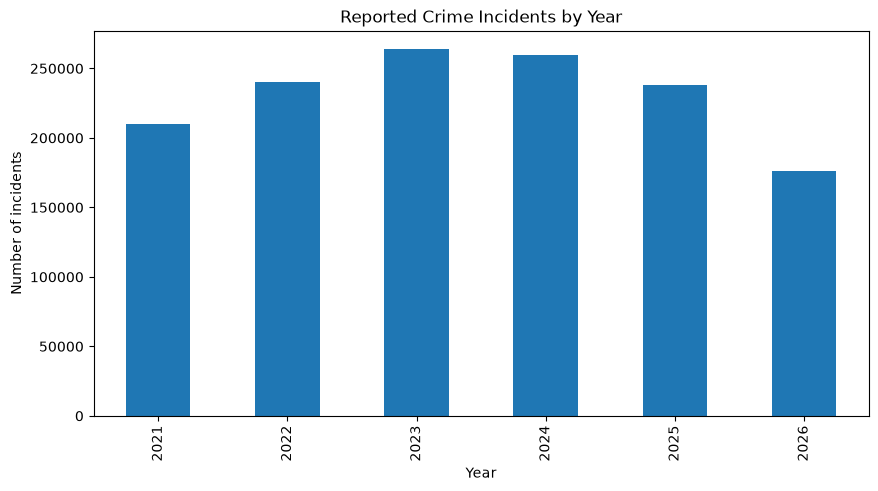

In [9]:
plt.figure(figsize=(10, 5))

crimes_by_year.plot(kind="bar")

plt.title("Reported Crime Incidents by Year")
plt.xlabel("Year")
plt.ylabel("Number of incidents")

plt.show()

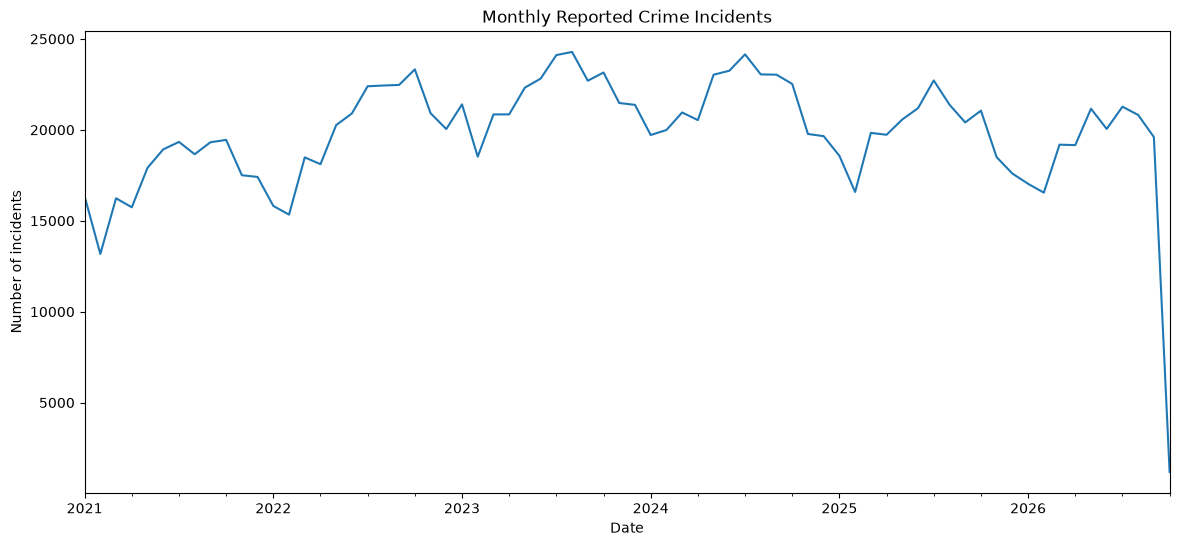

In [10]:
monthly_crimes = (
    df
    .set_index("date")
    .resample("ME")
    .size()
)

plt.figure(figsize=(14, 6))

monthly_crimes.plot()

plt.title("Monthly Reported Crime Incidents")
plt.xlabel("Date")
plt.ylabel("Number of incidents")

plt.show()

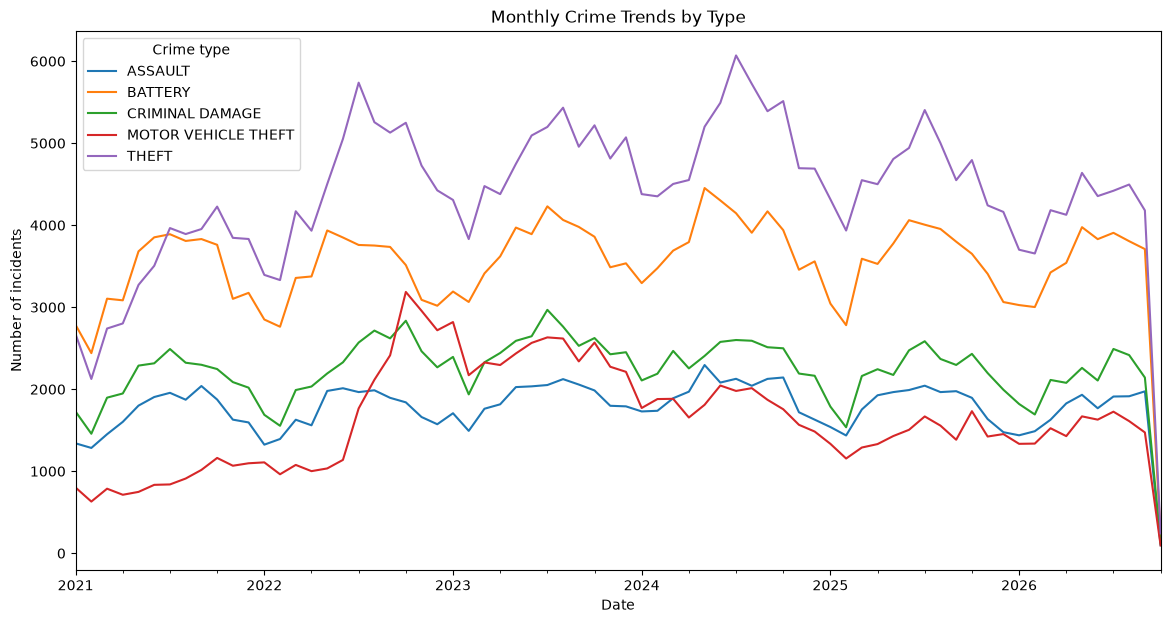

In [11]:
top5 = df["primary_type"].value_counts().head(5).index

monthly_by_type = (
    df[df["primary_type"].isin(top5)]
    .groupby([
        pd.Grouper(key="date", freq="ME"),
        "primary_type"
    ])
    .size()
    .unstack()
)

monthly_by_type.plot(figsize=(14, 7))

plt.title("Monthly Crime Trends by Type")
plt.xlabel("Date")
plt.ylabel("Number of incidents")
plt.legend(title="Crime type")

plt.show()

In [12]:
df["date"].dt.minute.value_counts().sort_index()

date
0     473745
1      18853
2       8122
3       8343
4       8313
5      20437
6       8049
7       8541
8       9084
9       8379
10     30138
11      8084
12      8924
13      8573
14      8398
15     48336
16      7923
17      8700
18      9118
19      8181
20     39714
21      7867
22      8547
23      8608
24      8469
25     20893
26      8246
27      8449
28      8651
29      7788
30    176072
31      6959
32      7865
33      7999
34      7923
35     20484
36      8285
37      8461
38      9115
39      7974
40     37920
41      7479
42      8586
43      8466
44      8164
45     52786
46      8155
47      8869
48      9041
49      7878
50     38306
51      7645
52      8360
53      8402
54      8206
55     19422
56      8191
57      8689
58      9106
59      7883
Name: count, dtype: int64

In [13]:
print("Exactly midnight:")
print((df["date"].dt.time == pd.Timestamp("00:00:00").time()).sum())

print("\nExactly noon:")
print((df["date"].dt.time == pd.Timestamp("12:00:00").time()).sum())

Exactly midnight:
55172

Exactly noon:
33692


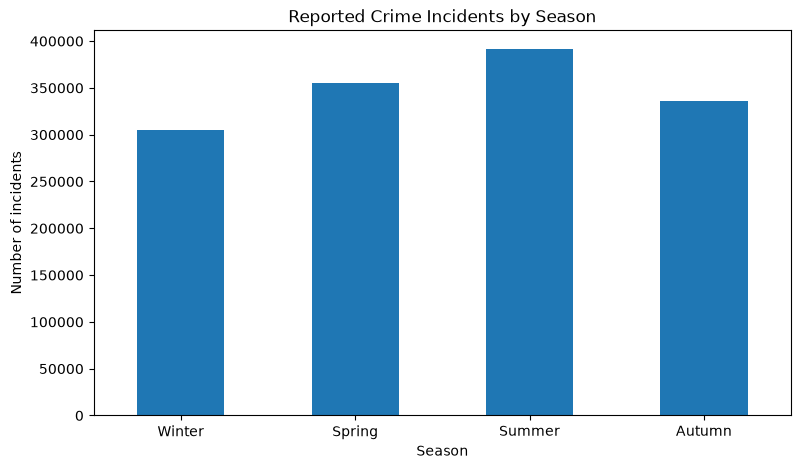

In [14]:
season_order = ["Winter", "Spring", "Summer", "Autumn"]

crimes_by_season = (
    df["season"]
    .value_counts()
    .reindex(season_order)
)

crimes_by_season.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Reported Crime Incidents by Season")
plt.xlabel("Season")
plt.ylabel("Number of incidents")
plt.xticks(rotation=0)

plt.show()

In [15]:
print(crimes_by_season)

season
Winter    305115
Spring    354924
Summer    391743
Autumn    336382
Name: count, dtype: int64


In [16]:
crimes_by_district = (
    df["district"]
    .value_counts()
    .sort_values(ascending=False)
)
top5_districts = crimes_by_district.head(5)
print(top5_districts)

district
8     88260
12    84247
6     82735
11    78169
4     77962
Name: count, dtype: int64


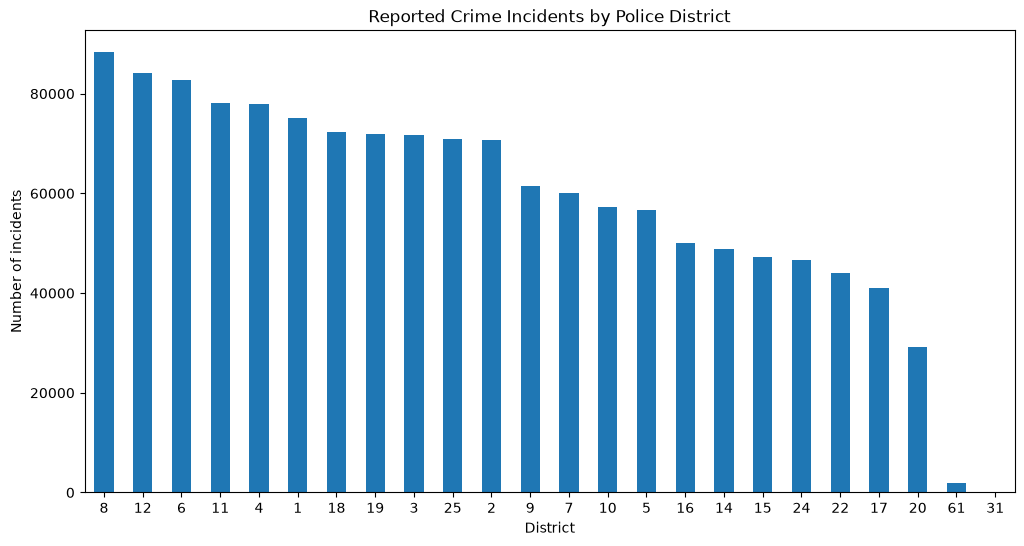

In [17]:
plt.figure(figsize=(12, 6))

crimes_by_district.plot(kind="bar")

plt.title("Reported Crime Incidents by Police District")
plt.xlabel("District")
plt.ylabel("Number of incidents")
plt.xticks(rotation=0)

plt.show()

In [18]:
district_crime = (
    df.groupby(["district", "primary_type"])
      .size()
      .reset_index(name="count")
)

top_crime_per_district = (
    district_crime
    .sort_values("count", ascending=False)
    .drop_duplicates("district")
    .sort_values("district")
)

top_crime_per_district

,district,primary_type,count
28,1,THEFT,26288
57,2,THEFT,15345
61,3,BATTERY,15208
91,4,BATTERY,15325
121,5,BATTERY,10993
151,6,BATTERY,16846
181,7,BATTERY,13783
236,8,THEFT,16561
240,9,BATTERY,11965
270,10,BATTERY,12964


In [19]:
invalid_districts = [31, 61]

df.loc[
    df["district"].isin(invalid_districts),
    "district"
] = pd.NA

df["district"] = df["district"].astype("Int64")

In [20]:
arrest_rate = df["arrest"].mean() * 100

print(f"Arrest rate: {arrest_rate:.2f}%")

Arrest rate: 13.59%


In [21]:
arrest_by_district = (
    df.dropna(subset=["district"])
      .groupby("district")["arrest"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

df_map = df.dropna(
    subset=["latitude", "longitude"]
).copy()

print(df_map.shape)

(1367657, 20)


In [22]:
df_map["lat_grid"] = df_map["latitude"].round(3)
df_map["lon_grid"] = df_map["longitude"].round(3)

hotspots = (
    df_map
    .groupby(["lat_grid", "lon_grid"])
    .size()
    .reset_index(name="crime_count")
    .sort_values("crime_count", ascending=False)
)

hotspots.head(10)

,lat_grid,lon_grid,crime_count
24735,41.882,-87.628,3099
37986,41.976,-87.905,1689
25014,41.884,-87.628,1611
22814,41.867,-87.626,1492
14729,41.789,-87.741,1415
9669,41.755,-87.742,1385
36287,41.963,-87.656,1200
13078,41.778,-87.616,1130
26066,41.892,-87.626,1127
22906,41.868,-87.630,1080


In [23]:
df_map_clean = df_map[
    ~(
        (df_map["latitude"] < 41) |
        (df_map["longitude"] < -88.5)
    )
].copy()

df_map_clean["lat_grid"] = df_map_clean["latitude"].round(3)
df_map_clean["lon_grid"] = df_map_clean["longitude"].round(3)

hotspots = (
    df_map_clean
    .groupby(["lat_grid", "lon_grid"])
    .size()
    .reset_index(name="crime_count")
    .sort_values("crime_count", ascending=False)
)

hotspots.head(10)


,lat_grid,lon_grid,crime_count
24734,41.882,-87.628,3099
37985,41.976,-87.905,1689
25013,41.884,-87.628,1611
22813,41.867,-87.626,1492
14728,41.789,-87.741,1415
9668,41.755,-87.742,1385
36286,41.963,-87.656,1200
13077,41.778,-87.616,1130
26065,41.892,-87.626,1127
22905,41.868,-87.630,1080
